# Chronic Disease Classification Using Machine Learning and Deep Learning

**Course:** Introduction to Machine Learning

**Institution:** African Leadership University (ALU)

**Project focus:** Applying traditional machine learning and deep learning techniques to a real-world health classification problem.

## Project objectives

1. Investigate a health-related classification problem using an eligible open dataset.
2. Perform exploratory data analysis and appropriate data preprocessing.
3. Train and compare traditional machine learning algorithms using Scikit-learn.
4. Develop and evaluate a neural network using TensorFlow/Keras.
5. Conduct systematic experiments and interpret the results using appropriate evaluation metrics.
6. Discuss model limitations and potential implications for chronic disease awareness, prevention, and management.

**Research question:** How effectively can traditional machine-learning and deep-learning models classify diabetes status using demographic, lifestyle, and health indicators, and how might data-driven insights from these models inform awareness-oriented wellness assessment?

In [ ]:

# Cell 1: Import the main libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Environment setup completed!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("TensorFlow version:", tf.__version__)


Environment setup completed!
NumPy version: 2.1.3
Pandas version: 2.2.3
Scikit-learn version: 1.6.1
TensorFlow version: 2.21.0


In [ ]:

# Cell 2: Load and inspect the raw dataset

from google.colab import files
import pandas as pd

uploaded = files.upload()

# Identify the uploaded CSV file
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if len(csv_files) != 1:
    raise ValueError(
        f"Expected one CSV file, but found {len(csv_files)}. "
        "Upload the dataset CSV file only."
    )

file_path = csv_files[0]
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Raw dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()


Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv
Dataset loaded successfully!
Raw dataset shape: (100000, 9)

First five rows:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



Column names:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [ ]:

# Cell 3: Data quality checks

# 1. Check missing values
print("Missing values per column:")
display(df.isnull().sum())

# 2. Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# 3. Check target classes
print("\nDiabetes target distribution:")
display(df["diabetes"].value_counts().sort_index())

print("\nTarget distribution as percentages:")
display(
    (df["diabetes"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

# 4. Check categorical values
print("\nUnique gender values:")
print(df["gender"].value_counts(dropna=False))

print("\nUnique smoking history values:")
print(df["smoking_history"].value_counts(dropna=False))

# 5. Check numerical ranges
print("\nNumerical summary:")
display(df.describe().T)


Missing values per column:


,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0



Number of duplicate rows:
3854

Diabetes target distribution:


,count
diabetes,
0,91500
1,8500



Target distribution as percentages:


,proportion
diabetes,
0,91.5
1,8.5



Unique gender values:
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

Unique smoking history values:
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.074850,0.263150,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.039420,0.194593,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.085000,0.278883,0.00,0.00,0.00,0.00,1.00


In [ ]:

# Cell 4: Investigate duplicates and validate the target

# Preserve the original dataset
df_raw = df.copy()

# Examine duplicate rows
duplicate_mask = df_raw.duplicated(keep=False)

print("Rows belonging to duplicate groups:", duplicate_mask.sum())
print("Rows after removing exact duplicates:", df_raw.drop_duplicates().shape[0])

print("\nExamples of repeated rows:")
display(df_raw[duplicate_mask].head(10))

# Verify target labels
print("\nUnique target labels:")
print(sorted(df_raw["diabetes"].unique()))

# Verify binary indicator columns
for col in ["hypertension", "heart_disease", "diabetes"]:
    print(f"\nUnique values in {col}:")
    print(sorted(df_raw[col].unique()))

# Check for negative values in numerical measurements
numeric_cols = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

print("\nMinimum values:")
display(df_raw[numeric_cols].min())

print("\nMaximum values:")
display(df_raw[numeric_cols].max())


Rows belonging to duplicate groups: 6939
Rows after removing exact duplicates: 96146

Examples of repeated rows:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
10,Female,53.0,0,0,never,27.32,6.1,85,0
14,Female,76.0,0,0,No Info,27.32,5.0,160,0
18,Female,42.0,0,0,No Info,27.32,5.7,80,0
41,Male,5.0,0,0,No Info,27.32,6.6,130,0
44,Female,67.0,0,0,No Info,27.32,3.5,160,0
51,Female,26.0,0,0,No Info,27.32,4.0,200,0
56,Male,30.0,0,0,No Info,27.32,6.6,140,0
62,Female,30.0,0,0,current,27.32,6.5,158,0
95,Male,19.0,0,0,never,27.32,6.1,80,0



Unique target labels:
[np.int64(0), np.int64(1)]

Unique values in hypertension:
[np.int64(0), np.int64(1)]

Unique values in heart_disease:
[np.int64(0), np.int64(1)]

Unique values in diabetes:
[np.int64(0), np.int64(1)]

Minimum values:


,0
age,0.08
bmi,10.01
HbA1c_level,3.50
blood_glucose_level,80.00



Maximum values:


,0
age,80.00
bmi,95.69
HbA1c_level,9.00
blood_glucose_level,300.00


In [ ]:

# Cell 5: Create the cleaned working dataset

# Remove exact duplicate rows
df_clean = df_raw.drop_duplicates().copy()

print("Original dataset shape:", df_raw.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Rows removed:", len(df_raw) - len(df_clean))

# Check for any remaining duplicate rows
print("Remaining exact duplicates:", df_clean.duplicated().sum())

# Check target distribution after removing duplicates
print("\nTarget counts:")
display(df_clean["diabetes"].value_counts().sort_index())

print("\nTarget proportions (%):")
display(
    (df_clean["diabetes"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

# Check for missing values after cleaning
print("\nMissing values:")
display(df_clean.isnull().sum())


Original dataset shape: (100000, 9)
Cleaned dataset shape: (96146, 9)
Rows removed: 3854
Remaining exact duplicates: 0

Target counts:


,count
diabetes,
0,87664
1,8482



Target proportions (%):


,proportion
diabetes,
0,91.18
1,8.82



Missing values:


,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [ ]:

# Cell 6: Explore feature types and class-level patterns

# Separate features from the target
X = df_clean.drop(columns=["diabetes"])
y = df_clean["diabetes"]

# Identify categorical and numerical features
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Feature count:", X.shape[1])
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

# Summarize numerical features by diabetes class
print("\nNumerical feature summaries by diabetes class:")
display(
    df_clean.groupby("diabetes")[numerical_features]
    .mean()
    .round(2)
    .T
)

# Explore categorical feature distributions
for col in categorical_features:
    print(f"\n{col} distribution by diabetes class (%):")
    display(
        pd.crosstab(
            df_clean[col],
            df_clean["diabetes"],
            normalize="columns"
        ).mul(100).round(2)
    )


Feature count: 8
Categorical features: ['gender', 'smoking_history']
Numerical features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']

Numerical feature summaries by diabetes class:


diabetes,0,1
age,39.94,60.93
hypertension,0.06,0.25
heart_disease,0.03,0.15
bmi,26.87,32.00
HbA1c_level,5.40,6.93
blood_glucose_level,132.82,194.03



gender distribution by diabetes class (%):


diabetes,0,1
gender,,
Female,58.99,52.43
Male,40.99,47.57
Other,0.02,0.00



smoking_history distribution by diabetes class (%):


diabetes,0,1
smoking_history,,
No Info,35.87,17.04
current,9.41,11.18
ever,4.02,5.56
former,8.79,18.75
never,35.43,39.34
not current,6.48,8.13


In [ ]:

# Cell 7: Split into training, validation, and test sets

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df_clean.drop(columns=["diabetes"])
y = df_clean["diabetes"]

# First, set aside 15% for the final test set
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Split the remaining 85% into training and validation
# 15% of the full dataset is approximately 17.65% of this remainder
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_train_val
)

# Display split sizes
print("Training set:", X_train.shape, "| Positive cases:", y_train.sum())
print("Validation set:", X_val.shape, "| Positive cases:", y_val.sum())
print("Test set:", X_test.shape, "| Positive cases:", y_test.sum())

# Verify target proportions in each split
print("\nDiabetes-positive percentage by split:")
print(f"Training:   {y_train.mean() * 100:.2f}%")
print(f"Validation: {y_val.mean() * 100:.2f}%")
print(f"Test:       {y_test.mean() * 100:.2f}%")


Training set: (67302, 8) | Positive cases: 5938
Validation set: (14422, 8) | Positive cases: 1272
Test set: (14422, 8) | Positive cases: 1272

Diabetes-positive percentage by split:
Training:   8.82%
Validation: 8.82%
Test:       8.82%


In [ ]:

# Cell 8: Define and apply preprocessing

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

categorical_features = ["gender", "smoking_history"]

numerical_features = [
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

# Define transformations
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

numerical_transformer = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_features),
        ("numerical", numerical_transformer, numerical_features)
    ],
    remainder="drop"
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test data without refitting
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert to NumPy arrays for model compatibility
X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

# Check processed dimensions and data quality
print("Training features:", X_train_processed.shape)
print("Validation features:", X_val_processed.shape)
print("Test features:", X_test_processed.shape)

print("\nMissing values after preprocessing:")
print("Training:", np.isnan(X_train_processed).sum())
print("Validation:", np.isnan(X_val_processed).sum())
print("Test:", np.isnan(X_test_processed).sum())

print("\nAll processed training values finite:",
      np.isfinite(X_train_processed).all())


Training features: (67302, 15)
Validation features: (14422, 15)
Test features: (14422, 15)

Missing values after preprocessing:
Training: 0
Validation: 0
Test: 0

All processed training values finite: True


In [ ]:

# Cell 9: Baseline Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Initialize the baseline model
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train using the training set
logistic_model.fit(X_train_processed, y_train)

# Predict validation labels and probabilities
y_val_pred_lr = logistic_model.predict(X_val_processed)
y_val_prob_lr = logistic_model.predict_proba(X_val_processed)[:, 1]

# Evaluate on validation data
print("BASELINE LOGISTIC REGRESSION — VALIDATION RESULTS")
print("-" * 55)
print(f"Accuracy:  {accuracy_score(y_val, y_val_pred_lr):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred_lr, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred_lr, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_val, y_val_pred_lr, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, y_val_prob_lr):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred_lr))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_pred_lr,
    target_names=["No diabetes (0)", "Diabetes (1)"],
    zero_division=0
))


BASELINE LOGISTIC REGRESSION — VALIDATION RESULTS
-------------------------------------------------------
Accuracy:  0.8850
Precision: 0.4270
Recall:    0.8892
F1-score:  0.5769
ROC-AUC:   0.9624

Confusion matrix:
[[11632  1518]
 [  141  1131]]

Classification report:
                 precision    recall  f1-score   support

No diabetes (0)       0.99      0.88      0.93     13150
   Diabetes (1)       0.43      0.89      0.58      1272

       accuracy                           0.88     14422
      macro avg       0.71      0.89      0.76     14422
   weighted avg       0.94      0.88      0.90     14422



In [ ]:

# Cell 10: Baseline Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Initialize the model
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train on the training set
random_forest_model.fit(X_train_processed, y_train)

# Predict validation labels and probabilities
y_val_pred_rf = random_forest_model.predict(X_val_processed)
y_val_prob_rf = random_forest_model.predict_proba(X_val_processed)[:, 1]

# Evaluate on validation data
print("BASELINE RANDOM FOREST — VALIDATION RESULTS")
print("-" * 55)
print(f"Accuracy:  {accuracy_score(y_val, y_val_pred_rf):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred_rf, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred_rf, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_val, y_val_pred_rf, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, y_val_prob_rf):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_pred_rf,
    target_names=["No diabetes (0)", "Diabetes (1)"],
    zero_division=0
))


BASELINE RANDOM FOREST — VALIDATION RESULTS
-------------------------------------------------------
Accuracy:  0.9635
Precision: 0.8301
Recall:    0.7374
F1-score:  0.7810
ROC-AUC:   0.9726

Confusion matrix:
[[12958   192]
 [  334   938]]

Classification report:
                 precision    recall  f1-score   support

No diabetes (0)       0.97      0.99      0.98     13150
   Diabetes (1)       0.83      0.74      0.78      1272

       accuracy                           0.96     14422
      macro avg       0.90      0.86      0.88     14422
   weighted avg       0.96      0.96      0.96     14422



In [ ]:

# Cell 11: Random Forest hyperparameter tuning

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Define the search space
param_distributions = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": randint(2, 15),
    "min_samples_leaf": randint(1, 8),
    "max_features": ["sqrt", "log2"],
    "class_weight": ["balanced", "balanced_subsample"]
}

# Base estimator
rf_search_base = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

# Search using training data only
rf_search = RandomizedSearchCV(
    estimator=rf_search_base,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

rf_search.fit(X_train_processed, y_train)

# Best configuration and cross-validation score
print("Best hyperparameters:")
print(rf_search.best_params_)

print(f"\nBest mean cross-validation F1-score: {rf_search.best_score_:.4f}")

# Evaluate the selected model on the validation set
tuned_rf_model = rf_search.best_estimator_

y_val_pred_tuned_rf = tuned_rf_model.predict(X_val_processed)
y_val_prob_tuned_rf = tuned_rf_model.predict_proba(X_val_processed)[:, 1]

print("\nTUNED RANDOM FOREST — VALIDATION RESULTS")
print("-" * 55)
print(f"Accuracy:  {accuracy_score(y_val, y_val_pred_tuned_rf):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred_tuned_rf, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred_tuned_rf, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_val, y_val_pred_tuned_rf, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, y_val_prob_tuned_rf):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred_tuned_rf))


Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [ ]:

# Cell 12: Compare baseline and tuned models

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

experiments = [
    {
        "Run": "LR_baseline",
        "Model": "Logistic Regression",
        "y_true": y_val,
        "y_pred": y_val_pred_lr,
        "y_prob": y_val_prob_lr
    },
    {
        "Run": "RF_baseline",
        "Model": "Random Forest",
        "y_true": y_val,
        "y_pred": y_val_pred_rf,
        "y_prob": y_val_prob_rf
    },
    {
        "Run": "RF_tuned",
        "Model": "Tuned Random Forest",
        "y_true": y_val,
        "y_pred": y_val_pred_tuned_rf,
        "y_prob": y_val_prob_tuned_rf
    }
]

results = []

for exp in experiments:
    results.append({
        "Run": exp["Run"],
        "Model": exp["Model"],
        "Accuracy": accuracy_score(exp["y_true"], exp["y_pred"]),
        "Precision": precision_score(
            exp["y_true"], exp["y_pred"], zero_division=0
        ),
        "Recall": recall_score(
            exp["y_true"], exp["y_pred"], zero_division=0
        ),
        "F1-score": f1_score(
            exp["y_true"], exp["y_pred"], zero_division=0
        ),
        "ROC-AUC": roc_auc_score(exp["y_true"], exp["y_prob"])
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


In [ ]:

# Cell 13: Visualize traditional ML model performance

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

for i, (_, row) in enumerate(results_df.iterrows()):
    values = [row[metric] for metric in metrics]
    ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=row["Model"]
    )

ax.set_ylabel("Score")
ax.set_title("Traditional Machine Learning Models — Validation Results")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Cell 14: Confusion matrix for tuned Random Forest

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_tuned_rf,
    display_labels=["No diabetes", "Diabetes"],
    cmap="Blues",
    values_format="d"
)

plt.title("Tuned Random Forest — Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Cell 15: ROC curve comparison

from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_val, y_val_prob_lr, name="Logistic Regression", ax=ax
)

RocCurveDisplay.from_predictions(
    y_val, y_val_prob_rf, name="Random Forest", ax=ax
)

RocCurveDisplay.from_predictions(
    y_val, y_val_prob_tuned_rf, name="Tuned Random Forest", ax=ax
)

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set_title("ROC Curves — Validation Set")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


In [ ]:

# Cell 16: Set up TensorFlow and the baseline neural network

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set reproducibility seeds
tf.keras.utils.set_random_seed(42)

# Define the neural network
def build_baseline_nn(input_dim):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    return model

nn_model = build_baseline_nn(X_train_processed.shape[1])

nn_model.summary()


In [ ]:

# Cell 17: Train the baseline neural network

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = nn_model.fit(
    X_train_processed,
    y_train.to_numpy(),
    validation_data=(X_val_processed, y_val.to_numpy()),
    epochs=40,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9267 - auc: 0.8877 - loss: 0.2043 - precision: 0.6367 - recall: 0.3954 - val_accuracy: 0.9570 - val_auc: 0.9604 - val_loss: 0.1198 - val_precision: 0.8221 - val_recall: 0.6541
Epoch 2/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9564 - auc: 0.9541 - loss: 0.1253 - precision: 0.8416 - recall: 0.6226 - val_accuracy: 0.9581 - val_auc: 0.9620 - val_loss: 0.1145 - val_precision: 0.8372 - val_recall: 0.6509
Epoch 3/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9594 - auc: 0.9574 - loss: 0.1176 - precision: 0.8765 - recall: 0.6285 - val_accuracy: 0.9597 - val_auc: 0.9635 - val_loss: 0.1101 - val_precision: 0.8679 - val_recall: 0.6407
Epoch 4/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9614 - auc: 0.9600 - loss: 0.1127 - precision: 0.9022 - recall: 0.6310 - val_accuracy: 0.9620 - val_auc: 0.9658 - val_loss: 0.1052 - val_precision: 0.8884 - val_recall: 0.6509
Epoch 5/40
263/263 ━━━━━━━━━━━━━

In [ ]:

# Cell 18: Neural network validation evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# Predict probabilities, then convert to labels using threshold 0.5
y_val_prob_nn = nn_model.predict(
    X_val_processed, verbose=0
).ravel()

y_val_pred_nn = (y_val_prob_nn >= 0.5).astype(int)

print("BASELINE NEURAL NETWORK — VALIDATION RESULTS")
print("-" * 55)
print(f"Accuracy:  {accuracy_score(y_val, y_val_pred_nn):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred_nn, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred_nn, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_val, y_val_pred_nn, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, y_val_prob_nn):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred_nn))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_pred_nn,
    target_names=["No diabetes (0)", "Diabetes (1)"],
    zero_division=0
))


BASELINE NEURAL NETWORK — VALIDATION RESULTS
-------------------------------------------------------
Accuracy:  0.9698
Precision: 0.9838
Recall:    0.6682
F1-score:  0.7959
ROC-AUC:   0.9771

Confusion matrix:
[[13136    14]
 [  422   850]]

Classification report:
                 precision    recall  f1-score   support

No diabetes (0)       0.97      1.00      0.98     13150
   Diabetes (1)       0.98      0.67      0.80      1272

       accuracy                           0.97     14422
      macro avg       0.98      0.83      0.89     14422
   weighted avg       0.97      0.97      0.97     14422



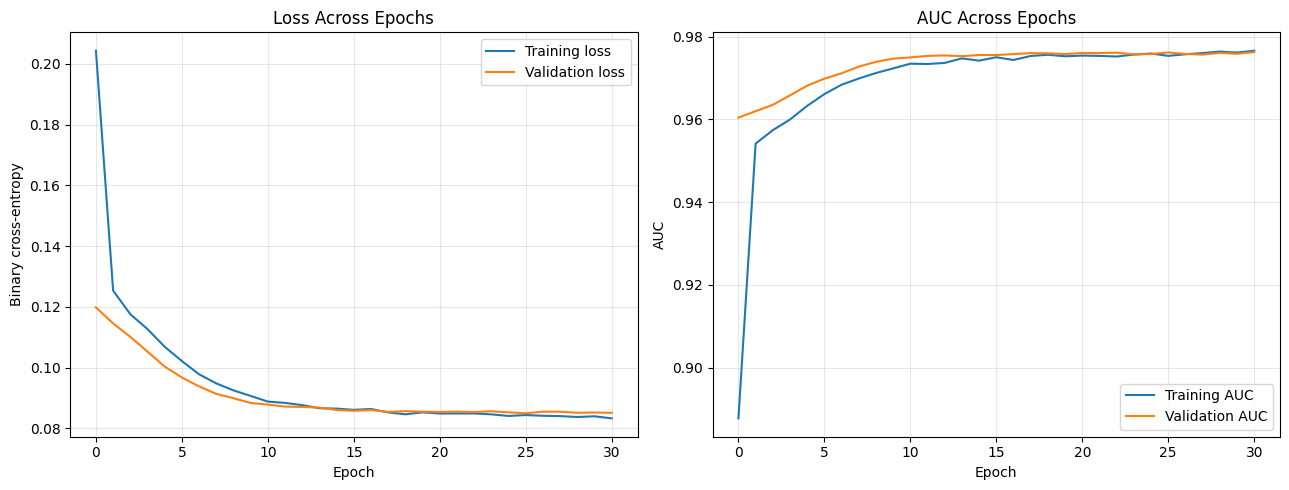

In [ ]:

# Cell 19: Neural network learning curves

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Loss
axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Loss Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# AUC
axes[1].plot(history.history["auc"], label="Training AUC")
axes[1].plot(history.history["val_auc"], label="Validation AUC")
axes[1].set_title("AUC Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Epochs completed:", len(history.history["loss"]))
print("Best validation loss:", round(min(history.history["val_loss"]), 4))
print(
    "Epoch with best validation loss:",
    int(np.argmin(history.history["val_loss"]) + 1)
)


In [ ]:

# Cell 20: Compare all current validation experiments

nn_result = pd.DataFrame([{
    "Run": "NN_baseline",
    "Model": "Neural Network",
    "Accuracy": accuracy_score(y_val, y_val_pred_nn),
    "Precision": precision_score(y_val, y_val_pred_nn, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_nn, zero_division=0),
    "F1-score": f1_score(y_val, y_val_pred_nn, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_nn)
}])

all_results_df = pd.concat(
    [results_df, nn_result],
    ignore_index=True
)

display(
    all_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


In [ ]:

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Calculate class weights using training data only
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

# Build a second neural network
tf.keras.utils.set_random_seed(42)

def build_tuned_nn(input_dim):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0005),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    return model

tuned_nn_model = build_tuned_nn(X_train_processed.shape[1])

tuned_nn_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

tuned_nn_history = tuned_nn_model.fit(
    X_train_processed,
    y_train.to_numpy(),
    validation_data=(X_val_processed, y_val.to_numpy()),
    epochs=40,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[tuned_nn_early_stopping],
    verbose=1
)


Class weights: {0: 0.5483834169871586, 1: 5.6670596160323345}
Epoch 1/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8131 - auc: 0.9357 - loss: 0.3307 - precision: 0.3077 - recall: 0.8949 - val_accuracy: 0.8708 - val_auc: 0.9623 - val_loss: 0.2786 - val_precision: 0.3984 - val_recall: 0.9127
Epoch 2/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8747 - auc: 0.9590 - loss: 0.2579 - precision: 0.4045 - recall: 0.8909 - val_accuracy: 0.8716 - val_auc: 0.9646 - val_loss: 0.2673 - val_precision: 0.4000 - val_recall: 0.9119
Epoch 3/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8785 - auc: 0.9623 - loss: 0.2463 - precision: 0.4131 - recall: 0.8944 - val_accuracy: 0.8741 - val_auc: 0.9670 - val_loss: 0.2516 - val_precision: 0.4050 - val_recall: 0.9119
Epoch 4/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8800 - auc: 0.9646 - loss: 0.2375 - precision: 0.4168 - recall: 0.9027 - val_accuracy: 0.8795 - val_auc: 0.9695 - val_loss: 0.2357 - val_precision

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)
import numpy as np

y_val_prob_tuned_nn = tuned_nn_model.predict(
    X_val_processed, verbose=0
).ravel()

y_val_pred_tuned_nn = (
    y_val_prob_tuned_nn >= 0.5
).astype(int)

tuned_nn_metrics = {
    "Run": "NN_tuned_weighted",
    "Model": "Tuned Neural Network",
    "Accuracy": accuracy_score(y_val, y_val_pred_tuned_nn),
    "Precision": precision_score(
        y_val, y_val_pred_tuned_nn, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_tuned_nn, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_tuned_nn, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_tuned_nn)
}

print("TUNED NEURAL NETWORK — VALIDATION RESULTS")

for metric, value in tuned_nn_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred_tuned_nn))

print("\nClassification report:")
print(classification_report(
    y_val, y_val_pred_tuned_nn,
    target_names=["No diabetes", "Diabetes"],
    zero_division=0
))

print("\nEpochs completed:", len(tuned_nn_history.history["loss"]))
print(
    "Best validation loss:",
    round(min(tuned_nn_history.history["val_loss"]), 4)
)
print(
    "Best validation-loss epoch:",
    int(np.argmin(tuned_nn_history.history["val_loss"]) + 1)
)


TUNED NEURAL NETWORK — VALIDATION RESULTS
Run: NN_tuned_weighted
Model: Tuned Neural Network
Accuracy: 0.8925
Precision: 0.4474
Recall: 0.9332
F1-score: 0.6048
ROC-AUC: 0.9769

Confusion matrix:
[[11684  1466]
 [   85  1187]]

Classification report:
              precision    recall  f1-score   support

 No diabetes       0.99      0.89      0.94     13150
    Diabetes       0.45      0.93      0.60      1272

    accuracy                           0.89     14422
   macro avg       0.72      0.91      0.77     14422
weighted avg       0.94      0.89      0.91     14422


Epochs completed: 29
Best validation loss: 0.1861
Best validation-loss epoch: 24


In [ ]:

# Add the tuned neural network to the existing results
nn_tuned_result = pd.DataFrame([tuned_nn_metrics])

all_results_df = pd.concat(
    [results_df, nn_result, nn_tuned_result],
    ignore_index=True
)

display(
    all_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


,Run,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,LR_baseline,Logistic Regression,0.8850,0.4270,0.8892,0.5769,0.9624
1,RF_baseline,Random Forest,0.9635,0.8301,0.7374,0.7810,0.9726
2,RF_tuned,Tuned Random Forest,0.9517,0.6978,0.7987,0.7449,0.9746
3,NN_baseline,Neural Network,0.9698,0.9838,0.6682,0.7959,0.9771
4,NN_tuned_weighted,Tuned Neural Network,0.8925,0.4474,0.9332,0.6048,0.9769


In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

gradient_boost_model = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_iter=200,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    class_weight="balanced",
    random_state=42
)

gradient_boost_model.fit(X_train_processed, y_train)

y_val_pred_gb = gradient_boost_model.predict(X_val_processed)
y_val_prob_gb = gradient_boost_model.predict_proba(
    X_val_processed
)[:, 1]

gb_metrics = {
    "Run": "GradientBoosting_baseline",
    "Model": "HistGradientBoosting",
    "Accuracy": accuracy_score(y_val, y_val_pred_gb),
    "Precision": precision_score(
        y_val, y_val_pred_gb, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_gb, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_gb, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_gb)
}

print("HISTOGRAM GRADIENT BOOSTING — VALIDATION RESULTS")
for metric, value in gb_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred_gb))


HISTOGRAM GRADIENT BOOSTING — VALIDATION RESULTS
Run: GradientBoosting_baseline
Model: HistGradientBoosting
Accuracy: 0.9058
Precision: 0.4822
Recall: 0.9175
F1-score: 0.6322
ROC-AUC: 0.9789

Confusion matrix:
[[11897  1253]
 [  105  1167]]


In [ ]:

# Combine all six experiments
gb_result = pd.DataFrame([gb_metrics])

all_results_df = pd.concat(
    [results_df, nn_result, nn_tuned_result, gb_result],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

display(
    all_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


,Run,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,NN_baseline,Neural Network,0.9698,0.9838,0.6682,0.7959,0.9771
1,RF_baseline,Random Forest,0.9635,0.8301,0.7374,0.7810,0.9726
2,RF_tuned,Tuned Random Forest,0.9517,0.6978,0.7987,0.7449,0.9746
3,GradientBoosting_baseline,HistGradientBoosting,0.9058,0.4822,0.9175,0.6322,0.9789
4,NN_tuned_weighted,Tuned Neural Network,0.8925,0.4474,0.9332,0.6048,0.9769
5,LR_baseline,Logistic Regression,0.8850,0.4270,0.8892,0.5769,0.9624


In [ ]:

from sklearn.metrics import precision_recall_curve, f1_score
import numpy as np
import pandas as pd

# Use validation probabilities to examine possible thresholds
precisions, recalls, thresholds = precision_recall_curve(
    y_val, y_val_prob_gb
)

# Precision and recall arrays contain one extra final element
f1_scores = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-12)
)

best_index = np.argmax(f1_scores)
best_threshold = float(thresholds[best_index])

print("THRESHOLD TUNING — VALIDATION SET")
print(f"Best threshold: {best_threshold:.4f}")
print(f"Precision: {precisions[best_index]:.4f}")
print(f"Recall: {recalls[best_index]:.4f}")
print(f"F1-score: {f1_scores[best_index]:.4f}")

# Evaluate the selected threshold on the same validation set
y_val_pred_gb_tuned_threshold = (
    y_val_prob_gb >= best_threshold
).astype(int)

print("\nConfusion matrix at selected threshold:")
print(confusion_matrix(y_val, y_val_pred_gb_tuned_threshold))


THRESHOLD TUNING — VALIDATION SET
Best threshold: 0.8725
Precision: 0.9754
Recall: 0.6863
F1-score: 0.8057

Confusion matrix at selected threshold:
[[13128    22]
 [  399   873]]


In [ ]:

threshold_result = {
    "Run": "GradientBoosting_tuned_threshold",
    "Model": "HistGradientBoosting (threshold tuned)",
    "Accuracy": accuracy_score(
        y_val, y_val_pred_gb_tuned_threshold
    ),
    "Precision": precision_score(
        y_val, y_val_pred_gb_tuned_threshold, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_gb_tuned_threshold, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_gb_tuned_threshold, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_gb)
}

threshold_result_df = pd.DataFrame([threshold_result])

all_results_df = pd.concat(
    [all_results_df, threshold_result_df],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

display(
    all_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


,Run,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,GradientBoosting_tuned_threshold,HistGradientBoosting (threshold tuned),0.9708,0.9754,0.6863,0.8057,0.9789
1,NN_baseline,Neural Network,0.9698,0.9838,0.6682,0.7959,0.9771
2,RF_baseline,Random Forest,0.9635,0.8301,0.7374,0.7810,0.9726
3,RF_tuned,Tuned Random Forest,0.9517,0.6978,0.7987,0.7449,0.9746
4,GradientBoosting_baseline,HistGradientBoosting,0.9058,0.4822,0.9175,0.6322,0.9789
5,NN_tuned_weighted,Tuned Neural Network,0.8925,0.4474,0.9332,0.6048,0.9769
6,LR_baseline,Logistic Regression,0.8850,0.4270,0.8892,0.5769,0.9624


FINAL TEST RESULTS — HISTGRADIENTBOOSTING
Threshold selected on validation set: 0.8725
Accuracy: 0.9718
Precision: 0.9748
Recall / Sensitivity: 0.6989
F1-score: 0.8141
ROC-AUC: 0.9770
Specificity: 0.9983

Confusion matrix:
[[13127    23]
 [  383   889]]

Classification report:
              precision    recall  f1-score   support

 No diabetes       0.97      1.00      0.98     13150
    Diabetes       0.97      0.70      0.81      1272

    accuracy                           0.97     14422
   macro avg       0.97      0.85      0.90     14422
weighted avg       0.97      0.97      0.97     14422



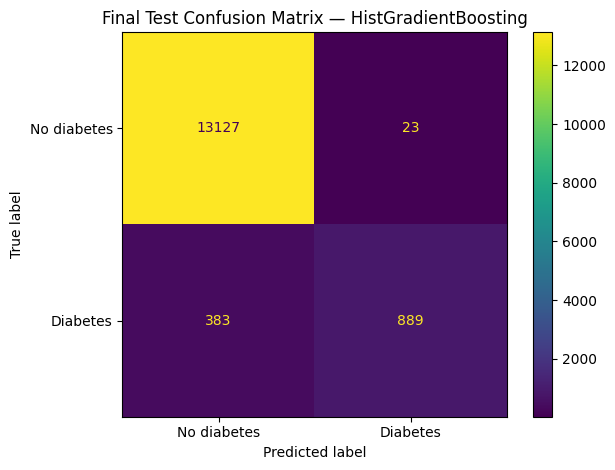

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Predict on the test set for the first time
y_test_prob_gb = gradient_boost_model.predict_proba(
    X_test_processed
)[:, 1]

# Reuse the threshold selected on the validation set
y_test_pred_gb = (
    y_test_prob_gb >= best_threshold
).astype(int)

# Final test metrics
final_test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred_gb),
    "Precision": precision_score(
        y_test, y_test_pred_gb, zero_division=0
    ),
    "Recall / Sensitivity": recall_score(
        y_test, y_test_pred_gb, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, y_test_pred_gb, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob_gb)
}

cm = confusion_matrix(y_test, y_test_pred_gb)
tn, fp, fn, tp = cm.ravel()

final_test_metrics["Specificity"] = tn / (tn + fp)

print("FINAL TEST RESULTS — HISTGRADIENTBOOSTING")
print(f"Threshold selected on validation set: {best_threshold:.4f}")

for metric, value in final_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion matrix:")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_test_pred_gb,
    target_names=["No diabetes", "Diabetes"],
    zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No diabetes", "Diabetes"]
).plot()
plt.title("Final Test Confusion Matrix — HistGradientBoosting")
plt.tight_layout()
plt.show()


In [ ]:

# Save the model comparison results
results_path = "model_comparison.csv"

all_results_df.to_csv(results_path, index=False)

print(f"Results saved to: {results_path}")
display(all_results_df)


Results saved to: model_comparison.csv


,Run,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,GradientBoosting_tuned_threshold,HistGradientBoosting (threshold tuned),0.970808,0.975419,0.686321,0.805722,0.978866
1,NN_baseline,Neural Network,0.969768,0.983796,0.668239,0.795880,0.977124
2,RF_baseline,Random Forest,0.963528,0.830088,0.737421,0.781016,0.972561
3,RF_tuned,Tuned Random Forest,0.951740,0.697802,0.798742,0.744868,0.974598
4,GradientBoosting_baseline,HistGradientBoosting,0.905838,0.482231,0.917453,0.632178,0.978866
5,NN_tuned_weighted,Tuned Neural Network,0.892456,0.447418,0.933176,0.604841,0.976946
6,LR_baseline,Logistic Regression,0.884967,0.426954,0.889151,0.576894,0.962374


In [ ]:

required_objects = [
    "gradient_boost_model",
    "preprocessor",
    "final_test_metrics",
    "best_threshold",
    "all_results_df"
]

for name in required_objects:
    print(f"{name}: {'Available' if name in globals() else 'MISSING'}")


gradient_boost_model: Available
preprocessor: Available
final_test_metrics: Available
best_threshold: Available
all_results_df: Available
